# Why rewarding a model for being right makes it overconfident

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Louiskq/open-rlcd/blob/main/notebooks/toy_rlcd.ipynb)

This is **Exp 0** of [open-rlcd](https://github.com/Louiskq/open-rlcd): a toy where the true probabilities are
known, so "calibrated" has an exact meaning. It runs on a CPU in about a minute. At the bottom, a slider
mixes the two rewards so you can watch calibration break.

> This repo presents *one reading* of RLCD (Reinforcement Learning for Calibrated Decisions). TypeSafe
> has not published RLCD; this is not their method.

**The setup.** A linear-softmax policy over 5 options. For each context $x$, the label $y$ is drawn from
a fixed ground-truth softmax $q(\cdot\mid x)$, and the policy class contains the truth. Every arm uses the
same model, optimiser, data stream and seeds. Only the reward differs:

| arm | reward for a sampled answer $a\sim p_\theta$ |
|---|---|
| supervised | log loss on $y$ (no sampling) |
| **RLVR** | $\mathbb{1}[a=y]$ (improper) |
| **RLCD-bandit** | $\mathbb{1}[a=y]\,/\,p_\theta(a)$, stop-gradient on the denominator |
| RLCD-bandit, clip 10 | the same, weight capped at 10 |
| RLCD-full | the proper score $S(p,y)=\log p_y$ through the RL code path |


In [1]:
import time
t_start = time.time()

try:
    import rlcd, toy  # noqa: F401
except ImportError:  # Google Colab: install straight from GitHub
    %pip install -q "open-rlcd @ git+https://github.com/Louiskq/open-rlcd.git"
    import rlcd, toy  # noqa: F401

from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from rlcd import estimators as E
from rlcd import plots
from toy import exp0 as X
from toy.run import arm_json, final_summary

%matplotlib inline


## 1. The identity that makes bandit feedback enough

If only the *sampled* answer can be checked, the reward $r=\mathbb{1}[a=y]/p_\theta(a)$ (denominator held
constant) turns REINFORCE into an unbiased estimator of the log-likelihood gradient:

$$\mathbb{E}_{a\sim p}\Big[\tfrac{\mathbb{1}[a=y]}{p(a)}\,\nabla\log p(a)\Big]=\sum_a p(a)\tfrac{\mathbb{1}[a=y]}{p(a)}\nabla\log p(a)=\nabla\log p(y).$$

Check it numerically. The same check is a unit test in the repo (`tests/test_estimators.py`).


In [2]:
rng = np.random.default_rng(0)
z = np.array([1.2, 0.3, -0.4, 0.8, -1.5])
p, y, n = E.softmax(z), 3, 200_000
bandit = E.Arm("bandit", "rlcd_bandit", samples=1, baseline="none")
g = E.logit_gradient(bandit, np.tile(z, (n, 1)), np.full(n, y), rng)
analytic = np.eye(5)[y] - p                       # grad of log p_y with respect to the logits
mean, se = g.mean(0), g.std(0, ddof=1) / np.sqrt(n)

rows = ["| option | analytic gradient | Monte Carlo mean (200k samples) | z-score |", "|---|---|---|---|"]
for k in range(5):
    rows.append(f"| {k} | {analytic[k]:+.4f} | {mean[k]:+.4f} ± {se[k]:.4f} | {(mean[k] - analytic[k]) / se[k]:+.1f} |")
display(Markdown("\n".join(rows)))
print(f"largest |z-score| = {np.abs((mean - analytic) / se).max():.1f}  (an unbiased estimator stays within about 3)")


| option | analytic gradient | Monte Carlo mean (200k samples) | z-score |
|---|---|---|---|
| 0 | -0.4263 | -0.4259 ± 0.0015 | +0.3 |
| 1 | -0.1733 | -0.1731 ± 0.0006 | +0.3 |
| 2 | -0.0861 | -0.0860 ± 0.0003 | +0.3 |
| 3 | +0.7143 | +0.7136 ± 0.0025 | -0.3 |
| 4 | -0.0286 | -0.0286 ± 0.0001 | +0.3 |

largest |z-score| = 0.3  (an unbiased estimator stays within about 3)


## 2. Train every arm

3 seeds, 3,000 Adam steps each. The evaluation set (10,000 contexts), the calibration set used to fit
one temperature per arm, and the training seeds are three disjoint sets.


In [3]:
cfg = replace(X.ToyConfig(), steps=3000, n_eval=10_000, n_cal=10_000, seeds=X.TRAIN_SEEDS[:3])
w_true = X.ground_truth(cfg)
eval_set = X.make_dataset(w_true, cfg.n_eval, X.EVAL_SEED)
cal_set = X.make_dataset(w_true, cfg.n_cal, X.CAL_SEED)

runs = {name: X.run_arm(arm, cfg, True, w_true, eval_set, cal_set) for name, arm in X.ARMS.items()}
summary = {name: final_summary(r) for name, r in runs.items()}

labels = {k: plots.ARM_STYLES[k].label for k in runs}
rows = ["| arm | ECE | mean confidence | accuracy | log loss | KL(truth ‖ model) | ECE after temperature scaling |", "|---|---|---|---|---|---|---|"]
for name in ("rlvr", "rlcd_bandit", "rlcd_bandit_clip10", "supervised", "rlcd_full"):
    s = summary[name]
    rows.append(
        f"| {labels[name]} | {s['raw']['ece']['mean']:.3f} | {s['raw']['mean_conf']['mean']:.3f} | "
        f"{s['raw']['acc']['mean']:.3f} | "
        f"{s['raw']['log_loss']['mean']:.3f} | {s['raw']['kl_to_truth']['mean']:.3f} | "
        f"{s['ts']['ece']['mean']:.3f} (T = {s['temperature']['mean']:.1f}) |"
    )
oracle = X.reference_metrics(eval_set)
rows.append(f"| *the true probabilities* | {oracle['ece']:.3f} | {oracle['mean_conf']:.3f} | {oracle['acc']:.3f} | {oracle['log_loss']:.3f} | 0 | |")
display(Markdown("\n".join(rows)))
gap = max(np.abs(np.asarray(a.curves[k]) - np.asarray(b.curves[k])).max()
          for a, b in zip(runs["supervised"], runs["rlcd_full"]) for k in a.curves)
print(f"largest difference between the supervised and RLCD-full curves, any metric / seed / step: {gap:.1e}")
print(f"log loss of predicting uniformly over 5 options: {np.log(5):.3f}")


  supervised           3 seeds  final ECE 0.0096  (0.8s)


  rlcd_full            3 seeds  final ECE 0.0096  (0.9s)


  rlcd_bandit          3 seeds  final ECE 0.0134  (1.2s)


  rlcd_bandit_clip10   3 seeds  final ECE 0.0648  (1.2s)


  rlvr                 3 seeds  final ECE 0.3697  (1.1s)


| arm | ECE | mean confidence | accuracy | log loss | KL(truth ‖ model) | ECE after temperature scaling |
|---|---|---|---|---|---|---|
| RLVR | 0.370 | 0.869 | 0.499 | 2.777 | 1.594 | 0.011 (T = 5.5) |
| RLCD-bandit | 0.013 | 0.504 | 0.503 | 1.212 | 0.006 | 0.013 (T = 1.0) |
| RLCD-bandit, clip 10 | 0.065 | 0.567 | 0.503 | 1.233 | 0.030 | 0.012 (T = 1.3) |
| Supervised log loss | 0.010 | 0.505 | 0.501 | 1.211 | 0.004 | 0.011 (T = 1.0) |
| RLCD-full | 0.010 | 0.505 | 0.501 | 1.211 | 0.004 | 0.011 (T = 1.0) |
| *the true probabilities* | 0.008 | 0.499 | 0.501 | 1.208 | 0 | |

largest difference between the supervised and RLCD-full curves, any metric / seed / step: 4.4e-16
log loss of predicting uniformly over 5 options: 1.609


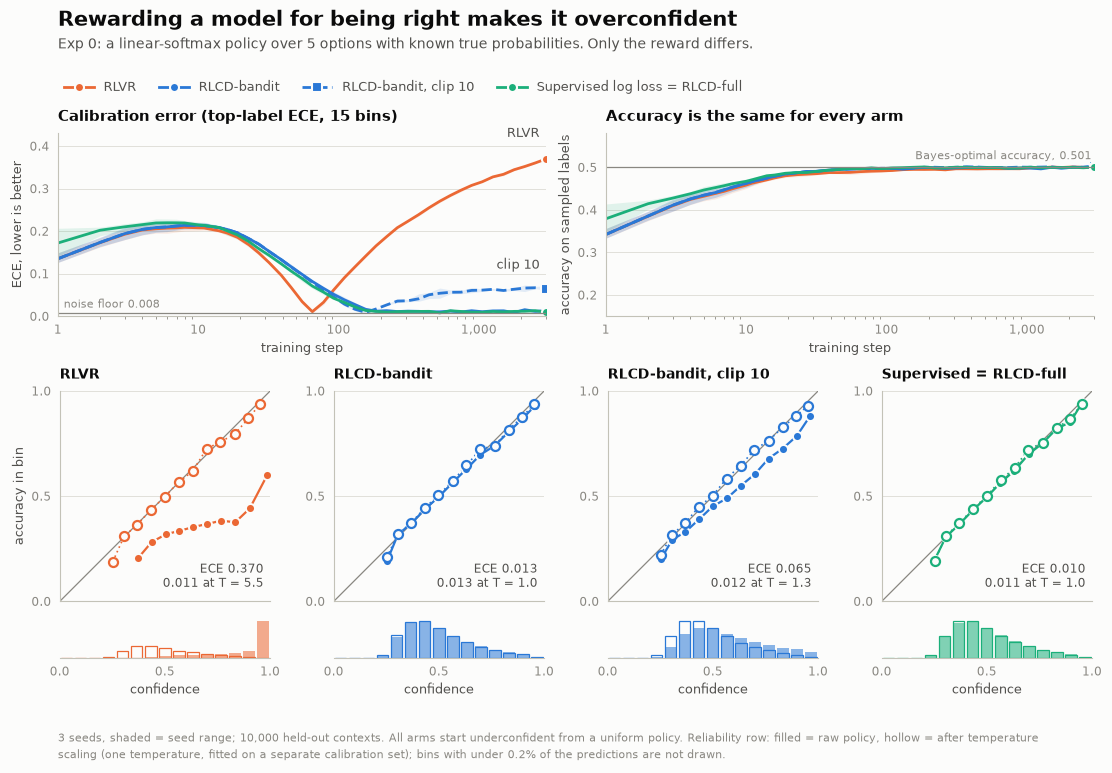

In [4]:
meta = {
    "config": X.config_dict(cfg),
    "seed_sets": {"train": list(cfg.seeds)},
    "oracle": oracle,
    "summary": summary,
}
data = {name: arm_json(X.ARMS[name], cfg, r) for name, r in runs.items()} | {"meta": meta}
fig = plots.fig_toy_overview(data, plots.LIGHT)
display(fig)
plt.close(fig)


Read the figure left to right:

* **Accuracy is the same** for every arm. RLVR is not worse at picking the answer.
* **Calibration is not.** All arms start underconfident (a uniform policy); RLVR crosses calibration
  early (the dip in its ECE curve) and keeps sharpening, so its mean confidence ends far above its
  accuracy (table above) and its log loss ends *worse than predicting uniformly*.
* **RLCD-bandit lands on the diagonal** and matches supervised log loss, using only the sampled answer.
* **Clipping the weight at 10 trades variance for bias**: options with true probability under 0.1 are
  under-weighted, so the policy ends up a little too sharp.
* **Supervised log loss and RLCD-full are the same curve** (see the printed difference): with fixed
  labels the full-distribution RLCD objective *is* log loss. RL is only needed when feedback is
  bandit-only or the outcome depends on the model's own actions.

**An honest wrinkle.** After one temperature (hollow markers) RLVR's reliability diagram snaps onto the
diagonal too. In this toy the policy class contains the truth, so RLVR only distorts the *scale* of the
logits and a scalar undoes it. Whether that holds for a real model is exactly what the pre-registered
experiments A2 / A3 (and hypothesis H5) test.


## 3. Mix the rewards: a slider

`reward = (1 - m) * 1[a=y] / p(a)  +  m * 1[a=y]`. At $m=0$ this is RLCD-bandit, at $m=1$ it is RLVR. The
estimator is linear in the reward, so this is the same as mixing the two gradients. Each position below is
trained once (2 seeds × 2,000 steps), then the sliders just scrub through the saved training runs.


In [5]:
MIXES = (0.0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0)
sweep_cfg = replace(cfg, steps=2000, n_eval=5000, n_cal=5000, seeds=cfg.seeds[:2])
sweep = X.mix_sweep(sweep_cfg, MIXES, verbose=False)
arms = {m: arm_json(E.Arm(f"mix_{m:g}", "rlcd_bandit", rlvr_mix=m), sweep_cfg, r) for m, r in sweep.items()}
print("trained", len(MIXES), "mixes")


trained 8 mixes


In [6]:
import ipywidgets as widgets

steps = arms[0.0]["steps"]
mix_slider = widgets.SelectionSlider(
    options=[(f"{m:.0%}", m) for m in MIXES], value=0.0, description="RLVR share",
    layout=widgets.Layout(width="520px"), style={"description_width": "90px"},
)
step_slider = widgets.SelectionSlider(
    options=[(f"{s:,}", i) for i, s in enumerate(steps)], index=len(steps) - 1,
    description="training step", layout=widgets.Layout(width="520px"), style={"description_width": "90px"},
)

def show(mix, step_idx):
    fig = plots.fig_toy_explorer(arms, mix, step_idx)
    display(fig)
    plt.close(fig)

widgets.interact(show, mix=mix_slider, step_idx=step_slider);


interactive(children=(SelectionSlider(description='RLVR share', layout=Layout(width='520px'), options=(('0%', …

If you are reading this on GitHub the sliders do not render; here is the same thing as a static strip
(final training step, left to right: 0%, 20%, 50%, 75%, 100% RLVR):


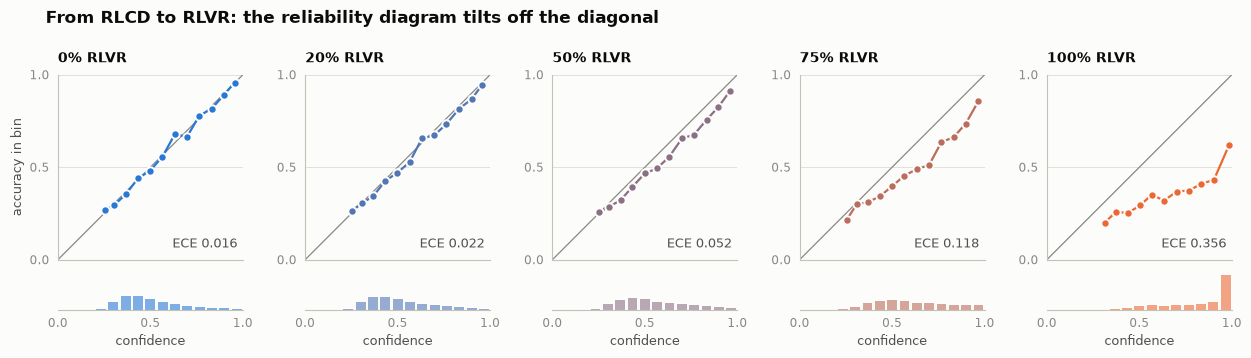

whole notebook: 11 s


In [7]:
fig = plots.fig_toy_gallery(arms, (0.0, 0.2, 0.5, 0.75, 1.0))
display(fig)
plt.close(fig)
print(f"whole notebook: {time.time() - t_start:.0f} s")


## What this does and does not show

* It shows the **mechanism**: an improper reward sharpens the model past what the outcomes justify, and a
  proper score rewarded through bandit feedback does not.
* It does **not** show that this happens in a 9B language model. That is Exp A / Exp B in the repo, with
  pre-registered hypotheses and the negative results reported.
* Small shares of RLVR (the left of the slider) are hard to tell from the noise floor; the damage grows
  gradually with the share, it is not a cliff.

Next: [the full results](https://github.com/Louiskq/open-rlcd#readme).
